In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

drive_path = "/content/drive/MyDrive"

for root, dirs, files in os.walk(drive_path):
    for file in files:
        if file.lower().endswith(".pth"):
            full_path = os.path.join(root, file)
            size_mb = os.path.getsize(full_path) / (1024 * 1024)

            print("File:", file)
            print("Location:", full_path)
            print("Size:", round(size_mb, 2), "MB")
            print("-" * 40)


File: maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth
Location: /content/drive/MyDrive/MaskRCNN/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth
Size: 169.84 MB
----------------------------------------


In [ ]:

import torch

file_path = "/content/drive/MyDrive/MaskRCNN/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth"

checkpoint = torch.load(
    file_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint type:", type(checkpoint))
print("Number of parameter entries:", len(checkpoint))

print("\nFirst 20 parameter names:")
for i, (name, value) in enumerate(checkpoint.items()):
    if i >= 20:
        break
    print(name, tuple(value.shape) if hasattr(value, "shape") else type(value))


Checkpoint type: <class 'collections.OrderedDict'>
Number of parameter entries: 307

First 20 parameter names:
backbone.body.conv1.weight (64, 3, 7, 7)
backbone.body.bn1.weight (64,)
backbone.body.bn1.bias (64,)
backbone.body.bn1.running_mean (64,)
backbone.body.bn1.running_var (64,)
backbone.body.layer1.0.conv1.weight (64, 64, 1, 1)
backbone.body.layer1.0.bn1.weight (64,)
backbone.body.layer1.0.bn1.bias (64,)
backbone.body.layer1.0.bn1.running_mean (64,)
backbone.body.layer1.0.bn1.running_var (64,)
backbone.body.layer1.0.conv2.weight (64, 64, 3, 3)
backbone.body.layer1.0.bn2.weight (64,)
backbone.body.layer1.0.bn2.bias (64,)
backbone.body.layer1.0.bn2.running_mean (64,)
backbone.body.layer1.0.bn2.running_var (64,)
backbone.body.layer1.0.conv3.weight (256, 64, 1, 1)
backbone.body.layer1.0.bn3.weight (256,)
backbone.body.layer1.0.bn3.bias (256,)
backbone.body.layer1.0.bn3.running_mean (256,)
backbone.body.layer1.0.bn3.running_var (256,)


In [ ]:

import torch

file_path = "/content/drive/MyDrive/MaskRCNN/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth"

checkpoint = torch.load(
    file_path,
    map_location="cpu",
    weights_only=True
)

print("Object type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nKeys inside the file:")
    print(list(checkpoint.keys())[:40])

    print("\nSample tensor names and shapes:")
    count = 0

    for key, value in checkpoint.items():
        if hasattr(value, "shape"):
            print(key, tuple(value.shape))
            count += 1

        if count >= 20:
            break


Object type: <class 'collections.OrderedDict'>

Keys inside the file:
['backbone.body.conv1.weight', 'backbone.body.bn1.weight', 'backbone.body.bn1.bias', 'backbone.body.bn1.running_mean', 'backbone.body.bn1.running_var', 'backbone.body.layer1.0.conv1.weight', 'backbone.body.layer1.0.bn1.weight', 'backbone.body.layer1.0.bn1.bias', 'backbone.body.layer1.0.bn1.running_mean', 'backbone.body.layer1.0.bn1.running_var', 'backbone.body.layer1.0.conv2.weight', 'backbone.body.layer1.0.bn2.weight', 'backbone.body.layer1.0.bn2.bias', 'backbone.body.layer1.0.bn2.running_mean', 'backbone.body.layer1.0.bn2.running_var', 'backbone.body.layer1.0.conv3.weight', 'backbone.body.layer1.0.bn3.weight', 'backbone.body.layer1.0.bn3.bias', 'backbone.body.layer1.0.bn3.running_mean', 'backbone.body.layer1.0.bn3.running_var', 'backbone.body.layer1.0.downsample.0.weight', 'backbone.body.layer1.0.downsample.1.weight', 'backbone.body.layer1.0.downsample.1.bias', 'backbone.body.layer1.0.downsample.1.running_mean', 'b

In [ ]:
from torchvision.models.detection import (
    MaskRCNN_ResNet50_FPN_Weights
)

categories = MaskRCNN_ResNet50_FPN_Weights.DEFAULT.meta["categories"]

print("Number of category entries:", len(categories))
print(categories)

Number of category entries: 91
['__background__', 'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'N/A', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'N/A', 'backpack', 'umbrella', 'N/A', 'N/A', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'N/A', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'N/A', 'dining table', 'N/A', 'N/A', 'toilet', 'N/A', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'N/A', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']


In [ ]:
import os

def search_drive_for_datasets(root_path):
    print(f"Searching {root_path} for potential dataset folders...")
    for root, dirs, files in os.walk(root_path):
        # Stop deep traversals in known hidden or library folders to save time
        if '.ipynb_checkpoints' in root or '.git' in root:
            continue

        # Look for annotations or structured dataset directories
        has_json = any(f.endswith('.json') for f in files)
        has_images = any(f.lower().endswith(('.png', '.jpg', '.jpeg')) for f in files)

        if has_json or (has_images and len(dirs) == 0):
            depth = root.replace(root_path, '').count(os.sep)
            if depth <= 3:
                print(f"\nPotential Dataset Location: {root}")
                print(f"  Directories: {dirs[:10]}")
                print(f"  Sample Files: {files[:10]}")

search_drive_for_datasets('/content/drive/MyDrive')

Searching /content/drive/MyDrive for potential dataset folders...


In [ ]:
import os
from collections import Counter

def deep_inspect_drive(root_path):
    print(f"Deep inspecting: {root_path}\n")
    file_summary = Counter()
    notable_archives = []
    notable_jsons = []
    image_count = 0

    for root, dirs, files in os.walk(root_path):
        # Exclude hidden and system directories
        dirs[:] = [d for d in dirs if not d.startswith('.') and d not in ('node_modules', 'venv', 'env')]

        for file in files:
            ext = os.path.splitext(file)[1].lower()
            file_summary[ext] += 1
            full_path = os.path.join(root, file)

            if ext in ('.zip', '.tar', '.gz', '.rar'):
                notable_archives.append((full_path, os.path.getsize(full_path) / (1024*1024)))
            elif ext == '.json':
                notable_jsons.append(full_path)
            elif ext in ('.jpg', '.jpeg', '.png', '.bmp', '.webp'):
                image_count += 1

    print("--- File Extension Summary ---")
    for ext, count in file_summary.items():
        print(f"{ext or 'No Extension'}: {count} files")

    if notable_archives:
        print("\n--- Found Archives ---")
        for path, size_mb in notable_archives[:10]:
            print(f"{path} ({size_mb:.2f} MB)")

    if notable_jsons:
        print("\n--- Found JSON Files ---")
        for path in notable_jsons[:10]:
            print(path)

    print(f"\nTotal Image Files Found: {image_count}")

deep_inspect_drive('/content/drive/MyDrive')


Deep inspecting: /content/drive/MyDrive

--- File Extension Summary ---

Total Image Files Found: 0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/TrafficDataset"

print(os.listdir(dataset_path))

['traffic_detector_dataset']


In [ ]:
import os

dataset_path = "/content/drive/MyDrive/TrafficDataset/traffic_detector_dataset"

print("Dataset contents:")
print(os.listdir(dataset_path))

Dataset contents:
['train.json', 'val.json', 'val', 'train']


In [ ]:
import os
import json
from pathlib import Path
from collections import Counter

dataset_path = Path(
    "/content/drive/MyDrive/TrafficDataset/traffic_detector_dataset"
)

# Count images in each folder
for split in ["train", "val"]:
    folder = dataset_path / split

    images = [
        p for p in folder.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    ]

    print(f"\n{split.upper()} images:", len(images))

# Inspect annotation JSON files
for filename in ["train.json", "val.json"]:
    filepath = dataset_path / filename

    print(f"\n--- {filename} ---")

    with open(filepath, "r", encoding="utf-8") as f:
        data = json.load(f)

    print("Top-level type:", type(data).__name__)

    if isinstance(data, dict):
        print("Top-level keys:", list(data.keys()))

        for key, value in data.items():
            if isinstance(value, list):
                print(f"{key}: {len(value)} items")

    elif isinstance(data, list):
        print("Number of records:", len(data))

    print("Sample content:")
    print(json.dumps(data, indent=2)[:2000])


TRAIN images: 167

VAL images: 71

--- train.json ---
Top-level type: dict
Top-level keys: ['images', 'categories', 'annotations']
images: 168 items
categories: 8 items
annotations: 272 items
Sample content:
{
  "images": [
    {
      "height": 600,
      "width": 800,
      "id": 0,
      "file_name": "bicycle1.jpg"
    },
    {
      "height": 600,
      "width": 800,
      "id": 1,
      "file_name": "bicycle10.jpg"
    },
    {
      "height": 600,
      "width": 800,
      "id": 2,
      "file_name": "bicycle11.jpg"
    },
    {
      "height": 600,
      "width": 800,
      "id": 3,
      "file_name": "bicycle12.jpg"
    },
    {
      "height": 600,
      "width": 800,
      "id": 4,
      "file_name": "bicycle13.jpg"
    },
    {
      "height": 600,
      "width": 800,
      "id": 5,
      "file_name": "bicycle14.jpg"
    },
    {
      "height": 600,
      "width": 800,
      "id": 6,
      "file_name": "bicycle15.jpg"
    },
    {
      "height": 600,
      "width": 800,
 

In [ ]:
import json
from pathlib import Path
from collections import Counter

dataset_path = Path(
    "/content/drive/MyDrive/TrafficDataset/traffic_detector_dataset"
)

for split in ["train", "val"]:
    print(f"\n{'=' * 15} {split.upper()} {'=' * 15}")

    json_path = dataset_path / f"{split}.json"
    image_dir = dataset_path / split

    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    # Show the eight category names and IDs
    print("\nCategories:")
    for category in data["categories"]:
        print(category)

    # Check annotation fields and segmentation information
    annotations = data["annotations"]
    print("\nAnnotation fields:")
    print(list(annotations[0].keys()) if annotations else "No annotations")

    segmentation_types = Counter()
    segmentation_missing = 0

    for ann in annotations:
        segmentation = ann.get("segmentation")

        if segmentation is None:
            segmentation_missing += 1
        else:
            segmentation_types[type(segmentation).__name__] += 1

    print("Segmentation types:", dict(segmentation_types))
    print("Annotations without segmentation:", segmentation_missing)

    # Check whether all JSON-listed images exist
    missing = [
        item["file_name"]
        for item in data["images"]
        if not (image_dir / item["file_name"]).exists()
    ]

    print("\nImages listed in JSON:", len(data["images"]))
    print("Images missing from folder:", len(missing))
    print("Missing image examples:", missing[:10])

    # Count images including GIFs
    extensions = {
        ".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif"
    }

    image_files = [
        p for p in image_dir.rglob("*")
        if p.suffix.lower() in extensions
    ]

    print("Image files found (including GIF):", len(image_files))


=============== TRAIN ===============

Categories:
{'supercategory': 'bicycle', 'id': 0, 'name': 'bicycle'}
{'supercategory': 'bus', 'id': 1, 'name': 'bus'}
{'supercategory': 'car', 'id': 2, 'name': 'car'}
{'supercategory': 'motorcycle', 'id': 3, 'name': 'motorcycle'}
{'supercategory': 'person', 'id': 4, 'name': 'person'}
{'supercategory': 'stop sign', 'id': 5, 'name': 'stop sign'}
{'supercategory': 'traffic light', 'id': 6, 'name': 'traffic light'}
{'supercategory': 'truck', 'id': 7, 'name': 'truck'}

Annotation fields:
['segmentation', 'iscrowd', 'area', 'image_id', 'bbox', 'category_id', 'id']
Segmentation types: {'list': 272}
Annotations without segmentation: 0

Images listed in JSON: 168
Images missing from folder: 0
Missing image examples: []
Image files found (including GIF): 168

=============== VAL ===============

Categories:
{'supercategory': 'bicycle', 'id': 0, 'name': 'bicycle'}
{'supercategory': 'bus', 'id': 1, 'name': 'bus'}
{'supercategory': 'car', 'id': 2, 'name': 'ca

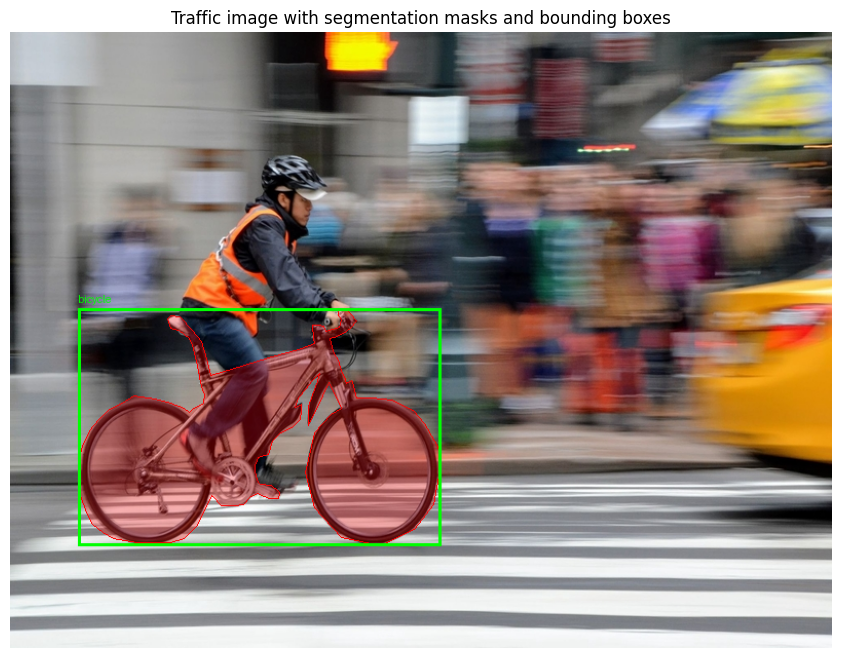

In [ ]:
import json
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

dataset_path = Path(
    "/content/drive/MyDrive/TrafficDataset/traffic_detector_dataset"
)

with open(dataset_path / "train.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Find an image that has an object annotation
image_info = None
annotations = []

for img in data["images"]:
    anns = [
        ann for ann in data["annotations"]
        if ann["image_id"] == img["id"]
        and ann.get("segmentation")
    ]

    if anns:
        image_info = img
        annotations = anns
        break

image_path = dataset_path / "train" / image_info["file_name"]
image = Image.open(image_path).convert("RGB")

# Draw segmentation polygons over the image
overlay = Image.new("RGBA", image.size, (0, 0, 0, 0))
draw = ImageDraw.Draw(overlay)

category_names = {
    cat["id"]: cat["name"]
    for cat in data["categories"]
}

for ann in annotations:
    for polygon in ann["segmentation"]:
        if len(polygon) >= 6 and len(polygon) % 2 == 0:
            points = [
                (polygon[i], polygon[i + 1])
                for i in range(0, len(polygon), 2)
            ]

            draw.polygon(
                points,
                fill=(255, 0, 0, 75),
                outline=(255, 0, 0, 255)
            )

    x, y, w, h = ann["bbox"]
    label = category_names[ann["category_id"]]

    draw.rectangle(
        [x, y, x + w, y + h],
        outline=(0, 255, 0, 255),
        width=3
    )
    draw.text((x, max(0, y - 15)), label, fill=(0, 255, 0, 255))

result = Image.alpha_composite(image.convert("RGBA"), overlay)

plt.figure(figsize=(12, 8))
plt.imshow(result)
plt.axis("off")
plt.title("Traffic image with segmentation masks and bounding boxes")
plt.show()

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Please enable a GPU in Colab:")
    print("Runtime > Change runtime type > T4 GPU (if available)")

PyTorch version: 2.11.0+cpu
GPU available: False
Please enable a GPU in Colab:
Runtime > Change runtime type > T4 GPU (if available)


In [ ]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

2.11.0+cu130
True
Tesla T4


In [ ]:
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

DATASET_DIR = Path("/content/drive/MyDrive/TrafficDataset/traffic_detector_dataset")
WEIGHTS_PATH = Path(
    "/content/drive/MyDrive/MaskRCNN/"
    "maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth"
)

print("Dataset folder exists:", DATASET_DIR.exists())
print("Train annotations exist:", (DATASET_DIR / "train.json").exists())
print("Validation annotations exist:", (DATASET_DIR / "val.json").exists())
print("Pretrained weights exist:", WEIGHTS_PATH.exists())

if WEIGHTS_PATH.exists():
    print(
        "Pretrained weights size (MB):",
        round(WEIGHTS_PATH.stat().st_size / (1024 * 1024), 2)
    )

Mounted at /content/drive
Dataset folder exists: True
Train annotations exist: True
Validation annotations exist: True
Pretrained weights exist: True
Pretrained weights size (MB): 169.84


In [ ]:
import torch
import torchvision

from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the Mask R-CNN architecture without downloading weights
model = maskrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None
)

# Load your existing COCO-pretrained weights
checkpoint = torch.load(
    str(WEIGHTS_PATH),
    map_location="cpu",
    weights_only=True
)

# Some checkpoints store the weights inside a dictionary
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]

model.load_state_dict(checkpoint)

# 8 traffic classes + 1 background class
num_classes = 9

# Replace the bounding-box prediction head
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features, num_classes
)

# Replace the instance-mask prediction head
in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
hidden_layer = 256

model.roi_heads.mask_predictor = MaskRCNNPredictor(
    in_features_mask,
    hidden_layer,
    num_classes
)

model.to(device)

print("Model loaded successfully!")
print("Device:", device)
print("Number of classes including background:", num_classes)
print("Torchvision version:", torchvision.__version__)

Model loaded successfully!
Device: cuda
Number of classes including background: 9
Torchvision version: 0.26.0+cu130


### Custom PyTorch Dataset for Mask R-CNN
Now we will define a custom dataset class `TrafficDataset` that:
1. Loads COCO images and annotations using the standard `pycocotools` library.
2. Converts polygon boundaries into binary instance masks (`[num_instances, height, width]`).
3. Converts COCO bounding boxes `[x, y, width, height]` to PyTorch-compatible `[xmin, ymin, xmax, ymax]` formats.
4. Map class labels from 0-7 in the source annotations to 1-8 for training (0 represents the background).
5. Filters out instances with invalid bounding box dimensions.

In [ ]:
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pycocotools.coco import COCO
import torchvision.transforms.functional as F
from pycocotools import mask as coco_mask

class TrafficDataset(Dataset):
    def __init__(self, root_dir, annotation_file, transforms=None):
        self.root_dir = root_dir
        self.coco = COCO(annotation_file)
        self.ids = list(sorted(self.coco.imgs.keys()))
        self.transforms = transforms

    def __getitem__(self, index):
        coco = self.coco
        img_id = self.ids[index]
        ann_ids = coco.getAnnIds(imgIds=img_id)
        coco_annotation = coco.loadAnns(ann_ids)

        # Load image details
        img_info = coco.loadImgs(img_id)[0]
        path = img_info['file_name']
        h_img, w_img = img_info['height'], img_info['width']
        img_path = os.path.join(self.root_dir, path)
        image = Image.open(img_path).convert("RGB")

        num_objs = len(coco_annotation)

        boxes = []
        labels = []
        masks = []
        areas = []
        iscrowd = []

        for i in range(num_objs):
            ann = coco_annotation[i]

            # Map COCO category_id (0-7) to 1-8 for Mask R-CNN training (0 is background)
            category_id = ann['category_id']
            label = category_id + 1

            # Bounding box conversion: [x, y, w, h] -> [xmin, ymin, xmax, ymax]
            xmin, ymin, w, h = ann['bbox']
            xmax = xmin + w
            ymax = ymin + h

            # Guard against invalid box dimensions
            if xmax <= xmin or ymax <= ymin:
                continue

            # Handle segmentation conversion to binary mask safely
            segm = ann.get('segmentation')
            if segm is None:
                continue

            if isinstance(segm, list):
                # Polygon format
                valid_polygons = [np.array(p, dtype=np.float32) for p in segm if len(p) >= 6]
                if not valid_polygons:
                    continue
                rles = coco_mask.frPyObjects([p.tolist() for p in valid_polygons], h_img, w_img)
                rle = coco_mask.merge(rles)
                mask = coco_mask.decode(rle)
            elif isinstance(segm, dict):
                # RLE format
                if isinstance(segm['counts'], list):
                    rle = coco_mask.frPyObjects(segm, h_img, w_img)
                    mask = coco_mask.decode(rle)
                else:
                    mask = coco_mask.decode(segm)
            else:
                continue

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(label)
            masks.append(mask)
            areas.append(ann.get('area', w * h))
            iscrowd.append(ann.get('iscrowd', 0))

        # Convert everything into torch.Tensors
        boxes = torch.as_tensor(boxes, dtype=torch.float32) if boxes else torch.zeros((0, 4), dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64) if labels else torch.zeros((0,), dtype=torch.int64)
        masks = torch.as_tensor(np.array(masks), dtype=torch.uint8) if masks else torch.zeros((0, image.size[1], image.size[0]), dtype=torch.uint8)
        areas = torch.as_tensor(areas, dtype=torch.float32) if areas else torch.zeros((0,), dtype=torch.float32)
        iscrowd = torch.as_tensor(iscrowd, dtype=torch.int64) if iscrowd else torch.zeros((0,), dtype=torch.int64)
        image_id = torch.tensor([img_id])

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": image_id,
            "area": areas,
            "iscrowd": iscrowd
        }

        if self.transforms is not None:
            image, target = self.transforms(image, target)
        else:
            # Default PIL to Tensor convert
            image = F.to_tensor(image)

        return image, target

    def __len__(self):
        return len(self.ids)

def collate_fn(batch):
    return tuple(zip(*batch))

### Visualize Parsed Ground Truth Annotations
Let's load a sample image from our new dataset class and draw the bounding boxes and binary masks to verify everything parses correctly.

loading annotations into memory...
Done (t=0.56s)
creating index...
index created!


/tmp/ipykernel_443/825190814.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  rgb_color = plt.cm.get_cmap('tab10')(label)[:3]


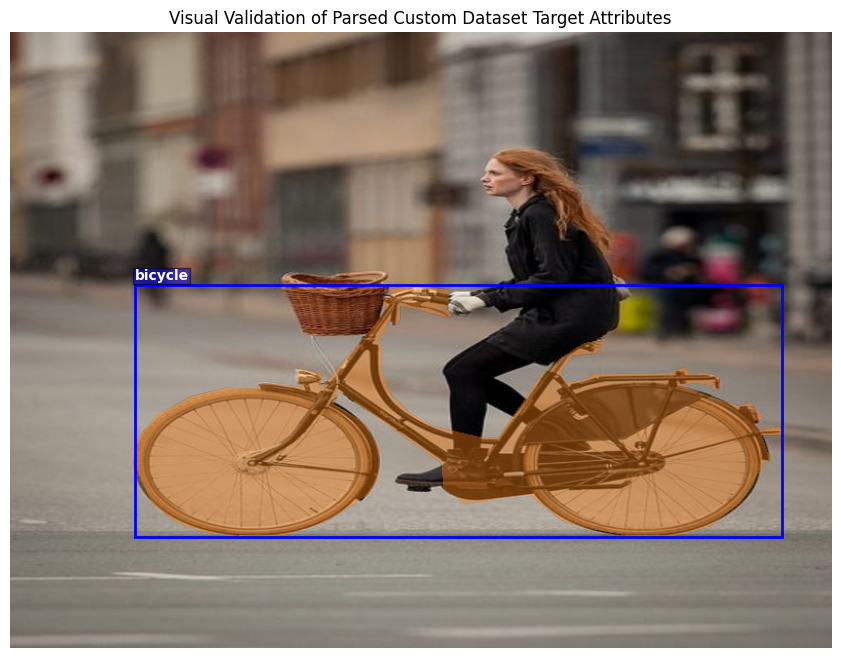

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

dataset_dir = "/content/drive/MyDrive/TrafficDataset/traffic_detector_dataset"
train_dataset = TrafficDataset(
    root_dir=os.path.join(dataset_dir, "train"),
    annotation_file=os.path.join(dataset_dir, "train.json")
)

# Get a sample
img, target = train_dataset[15]

# Setup plot
fig, ax = plt.subplots(1, figsize=(12, 8))
ax.imshow(img.permute(1, 2, 0).numpy())

# Draw bounding boxes and overlay masks
masks = target['masks'].numpy()
boxes = target['boxes'].numpy()
labels = target['labels'].numpy()

colors = ['red', 'blue', 'green', 'yellow', 'purple', 'orange', 'cyan', 'magenta', 'lime']
class_names = ['background', 'bicycle', 'bus', 'car', 'motorcycle', 'person', 'stop sign', 'traffic light', 'truck']

for i in range(len(boxes)):
    box = boxes[i]
    label = labels[i]
    mask = masks[i]

    # Plot Box
    rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], linewidth=2, edgecolor=colors[label % len(colors)], facecolor='none')
    ax.add_patch(rect)
    ax.text(box[0], box[1] - 5, class_names[label], color='white', weight='bold', bbox=dict(facecolor=colors[label % len(colors)], alpha=0.5, pad=1))

    # Create a colored semi-transparent mask overlay
    masked_img = np.zeros((mask.shape[0], mask.shape[1], 4))
    rgb_color = plt.cm.get_cmap('tab10')(label)[:3]
    masked_img[mask == 1] = [*rgb_color, 0.4]
    ax.imshow(masked_img)

plt.axis('off')
plt.title("Visual Validation of Parsed Custom Dataset Target Attributes")
plt.show()

### Training and Validation Pipeline Setup
We instantiate PyTorch `DataLoaders` with our custom detection `collate_fn`. We'll write the training loops, track overall loss components, and save the best checkpoint to Google Drive.

In [ ]:
import time
import pandas as pd

# Configure loaders
batch_size = 2
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

val_dataset = TrafficDataset(
    root_dir=os.path.join(dataset_dir, "val"),
    annotation_file=os.path.join(dataset_dir, "val.json")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

# Set optimizer and scheduler
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.002, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

print(f"DataLoaders configured! Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

loading annotations into memory...
Done (t=0.49s)
creating index...
index created!
DataLoaders configured! Train batches: 84, Val batches: 36


In [ ]:
import os
import time
import numpy as np
import pandas as pd
import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from pycocotools.coco import COCO
import torchvision.transforms.functional as F
from pycocotools import mask as coco_mask
from google.colab import drive
from torchvision.models.detection import maskrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

# Ensure Drive is mounted
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Initialize and configure the model with custom prediction heads
weights_path = "/content/drive/MyDrive/MaskRCNN/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth"
model = maskrcnn_resnet50_fpn(weights=None, weights_backbone=None)

# Load pretrained checkpoint
checkpoint = torch.load(weights_path, map_location="cpu", weights_only=True)
if isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    checkpoint = checkpoint["state_dict"]
model.load_state_dict(checkpoint)

num_classes = 9  # 8 traffic classes + 1 background class
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

in_features_mask = model.roi_heads.mask_predictor.conv5_mask.in_channels
hidden_layer = 256
model.roi_heads.mask_predictor = MaskRCNNPredictor(in_features_mask, hidden_layer, num_classes)
model.to(device)

# Define Dataset class
class TrafficDataset(Dataset):
    def __init__(self, root_dir, annotation_file, transforms=None):
        self.root_dir = root_dir
        self.coco = COCO(annotation_file)
        self.ids = list(sorted(self.coco.imgs.keys()))
        self.transforms = transforms

    def __getitem__(self, index):
        coco = self.coco
        img_id = self.ids[index]
        ann_ids = coco.getAnnIds(imgIds=img_id)
        coco_annotation = coco.loadAnns(ann_ids)

        img_info = coco.loadImgs(img_id)[0]
        path = img_info['file_name']
        h_img, w_img = img_info['height'], img_info['width']
        img_path = os.path.join(self.root_dir, path)
        image = Image.open(img_path).convert("RGB")

        num_objs = len(coco_annotation)
        boxes = []
        labels = []
        masks = []
        areas = []
        iscrowd = []

        for i in range(num_objs):
            ann = coco_annotation[i]
            category_id = ann['category_id']
            label = category_id + 1

            xmin, ymin, w, h = ann['bbox']
            xmax = xmin + w
            ymax = ymin + h

            if xmax <= xmin or ymax <= ymin:
                continue

            segm = ann.get('segmentation')
            if segm is None:
                continue

            if isinstance(segm, list):
                valid_polygons = [np.array(p, dtype=np.float32) for p in segm if len(p) >= 6]
                if not valid_polygons:
                    continue
                rles = coco_mask.frPyObjects([p.tolist() for p in valid_polygons], h_img, w_img)
                rle = coco_mask.merge(rles)
                mask = coco_mask.decode(rle)
            elif isinstance(segm, dict):
                if isinstance(segm['counts'], list):
                    rle = coco_mask.frPyObjects(segm, h_img, w_img)
                    mask = coco_mask.decode(rle)
                else:
                    mask = coco_mask.decode(segm)
            else:
                continue

            boxes.append([xmin, ymin, xmax, ymax])
            labels.append(label)
            masks.append(mask)
            areas.append(ann.get('area', w * h))
            iscrowd.append(ann.get('iscrowd', 0))

        boxes = torch.as_tensor(boxes, dtype=torch.float32) if boxes else torch.zeros((0, 4), dtype=torch.float32)
        labels = torch.as_tensor(labels, dtype=torch.int64) if labels else torch.zeros((0,), dtype=torch.int64)
        masks = torch.as_tensor(np.array(masks), dtype=torch.uint8) if masks else torch.zeros((0, image.size[1], image.size[0]), dtype=torch.uint8)
        areas = torch.as_tensor(areas, dtype=torch.float32) if areas else torch.zeros((0,), dtype=torch.float32)
        iscrowd = torch.as_tensor(iscrowd, dtype=torch.int64) if iscrowd else torch.zeros((0,), dtype=torch.int64)
        image_id = torch.tensor([img_id])

        target = {
            "boxes": boxes,
            "labels": labels,
            "masks": masks,
            "image_id": image_id,
            "area": areas,
            "iscrowd": iscrowd
        }

        if self.transforms is not None:
            image, target = self.transforms(image, target)
        else:
            image = F.to_tensor(image)

        return image, target

    def __len__(self):
        return len(self.ids)

def collate_fn(batch):
    return tuple(zip(*batch))

# Configure loader and optimization components
dataset_dir = "/content/drive/MyDrive/TrafficDataset/traffic_detector_dataset"
batch_size = 2

train_dataset = TrafficDataset(
    root_dir=os.path.join(dataset_dir, "train"),
    annotation_file=os.path.join(dataset_dir, "train.json")
)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.002, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

num_epochs = 10
best_loss = float('inf')
history = []

print("Starting training loop with corrected architecture and loader setup...")
for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0.0
    epoch_classifier_loss = 0.0
    epoch_box_reg_loss = 0.0
    epoch_mask_loss = 0.0

    start_time = time.time()

    for images, targets in train_loader:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += losses.item()
        epoch_classifier_loss += loss_dict['loss_classifier'].item()
        epoch_box_reg_loss += loss_dict['loss_box_reg'].item()
        epoch_mask_loss += loss_dict['loss_mask'].item()

    lr_scheduler.step()

    avg_loss = epoch_loss / len(train_loader)
    avg_cls = epoch_classifier_loss / len(train_loader)
    avg_box = epoch_box_reg_loss / len(train_loader)
    avg_mask = epoch_mask_loss / len(train_loader)

    elapsed = time.time() - start_time
    print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {avg_loss:.4f} (Cls: {avg_cls:.4f}, Box: {avg_box:.4f}, Mask: {avg_mask:.4f}) - Time: {elapsed:.1f}s")

    history.append({
        'epoch': epoch + 1,
        'loss': avg_loss,
        'loss_classifier': avg_cls,
        'loss_box_reg': avg_box,
        'loss_mask': avg_mask
    })

    if avg_loss < best_loss:
        best_loss = avg_loss
        save_dir = "/content/drive/MyDrive/MaskRCNN"
        os.makedirs(save_dir, exist_ok=True)
        save_path = os.path.join(save_dir, "traffic_maskrcnn_best.pth")
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': best_loss,
        }, save_path)
        print(f"  --> New best model saved to: {save_path}")

history_df = pd.DataFrame(history)
history_df.to_csv("/content/drive/MyDrive/MaskRCNN/training_history.csv", index=False)
print("Training completed successfully!")

Using device: cuda
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
Starting training loop with corrected architecture and loader setup...
Epoch [1/10] - Loss: 1.0039 (Cls: 0.2392, Box: 0.1365, Mask: 0.5503) - Time: 64.8s
  --> New best model saved to: /content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth
Epoch [2/10] - Loss: 0.5849 (Cls: 0.1328, Box: 0.1542, Mask: 0.2720) - Time: 63.6s
  --> New best model saved to: /content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth
Epoch [3/10] - Loss: 0.4135 (Cls: 0.0870, Box: 0.1280, Mask: 0.1846) - Time: 72.1s
  --> New best model saved to: /content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth
Epoch [4/10] - Loss: 0.3271 (Cls: 0.0636, Box: 0.0977, Mask: 0.1550) - Time: 73.2s
  --> New best model saved to: /content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth
Epoch [5/10] - Loss: 0.3018 (Cls: 0.0580, Box: 0.0888, Mask: 0.1472) - Time: 73.2s
  --> New best model saved to: /content/drive/MyDrive/Ma

### Training and Validation Pipeline Setup
We instantiate PyTorch `DataLoaders` with our custom detection `collate_fn`. We'll write the training loops, track overall loss components, and save the best checkpoint to Google Drive.

In [ ]:
import time
import pandas as pd

# Configure loaders
batch_size = 2
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    collate_fn=collate_fn
)

val_dataset = TrafficDataset(
    root_dir=os.path.join(dataset_dir, "val"),
    annotation_file=os.path.join(dataset_dir, "val.json")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    collate_fn=collate_fn
)

# Set optimizer and scheduler
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.SGD(params, lr=0.002, momentum=0.9, weight_decay=0.0005)
lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

print(f"DataLoaders configured! Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
DataLoaders configured! Train batches: 84, Val batches: 36


In [ ]:
num_epochs = 10
best_loss = float('inf')
history = []

print("Starting training loop...")
for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0.0
    epoch_classifier_loss = 0.0
    epoch_box_reg_loss = 0.0
    epoch_mask_loss = 0.0

    start_time = time.time()

    for images, targets in train_loader:
        images = list(image.to(device) for image in images)
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        epoch_loss += losses.item()
        epoch_classifier_loss += loss_dict['loss_classifier'].item()
        epoch_box_reg_loss += loss_dict['loss_box_reg'].item()
        epoch_mask_loss += loss_dict['loss_mask'].item()

    lr_scheduler.step()

    avg_loss = epoch_loss / len(train_loader)
    avg_cls = epoch_classifier_loss / len(train_loader)
    avg_box = epoch_box_reg_loss / len(train_loader)
    avg_mask = epoch_mask_loss / len(train_loader)

    elapsed = time.time() - start_time
    print(f"Epoch [{epoch+1}/{num_epochs}] - Loss: {avg_loss:.4f} (Cls: {avg_cls:.4f}, Box: {avg_box:.4f}, Mask: {avg_mask:.4f}) - Time: {elapsed:.1f}s")

    history.append({
        'epoch': epoch + 1,
        'loss': avg_loss,
        'loss_classifier': avg_cls,
        'loss_box_reg': avg_box,
        'loss_mask': avg_mask
    })

    # Save best checkpoint
    if avg_loss < best_loss:
        best_loss = avg_loss
        save_path = "/content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth"
        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': best_loss,
        }, save_path)
        print(f"  --> New best model saved to: {save_path}")

# Save history
history_df = pd.DataFrame(history)
history_df.to_csv("/content/drive/MyDrive/MaskRCNN/training_history.csv", index=False)
print("Training completed successfully!")

Starting training loop...
Epoch [1/10] - Loss: 0.2150 (Cls: 0.0347, Box: 0.0582, Mask: 0.1174) - Time: 64.0s
  --> New best model saved to: /content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth
Epoch [2/10] - Loss: 0.2126 (Cls: 0.0322, Box: 0.0568, Mask: 0.1182) - Time: 72.7s
  --> New best model saved to: /content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth
Epoch [3/10] - Loss: 0.2112 (Cls: 0.0334, Box: 0.0570, Mask: 0.1159) - Time: 73.8s
  --> New best model saved to: /content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth
Epoch [4/10] - Loss: 0.2082 (Cls: 0.0317, Box: 0.0554, Mask: 0.1163) - Time: 73.6s
  --> New best model saved to: /content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth
Epoch [5/10] - Loss: 0.2092 (Cls: 0.0320, Box: 0.0573, Mask: 0.1152) - Time: 73.6s
Epoch [6/10] - Loss: 0.2085 (Cls: 0.0320, Box: 0.0544, Mask: 0.1169) - Time: 67.1s
Epoch [7/10] - Loss: 0.2065 (Cls: 0.0317, Box: 0.0543, Mask: 0.1157) - Time: 67.3s
  --> New best model saved to: /conte

### Plotting Training Loss Curves
After training, we plot the progression of the classifier loss, bounding box regression loss, and mask segmentation loss.

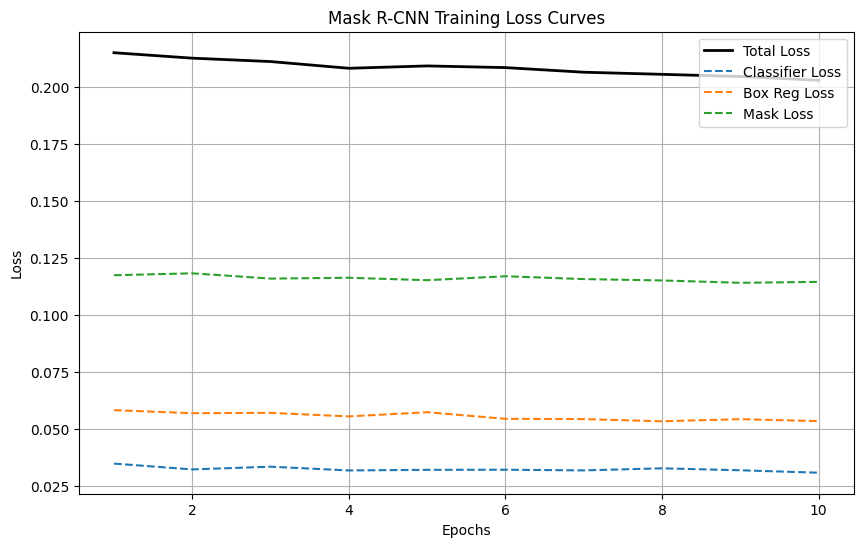

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os

history_path = "/content/drive/MyDrive/MaskRCNN/training_history.csv"
if os.path.exists(history_path):
    df = pd.read_csv(history_path)

    plt.figure(figsize=(10, 6))
    plt.plot(df['epoch'], df['loss'], label='Total Loss', color='black', linewidth=2)
    plt.plot(df['epoch'], df['loss_classifier'], label='Classifier Loss', linestyle='--')
    plt.plot(df['epoch'], df['loss_box_reg'], label='Box Reg Loss', linestyle='--')
    plt.plot(df['epoch'], df['loss_mask'], label='Mask Loss', linestyle='--')

    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.title('Mask R-CNN Training Loss Curves')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("Training history not found. Make sure the training loop completes first!")

### Evaluate Model Predictions
We switch the model to evaluation mode (`model.eval()`) and visualize validation predictions containing predicted boxes, class names, confidence scores, and instance masks.

loading annotations into memory...
Done (t=0.33s)
creating index...
index created!
Validation dataset contains 72 samples.


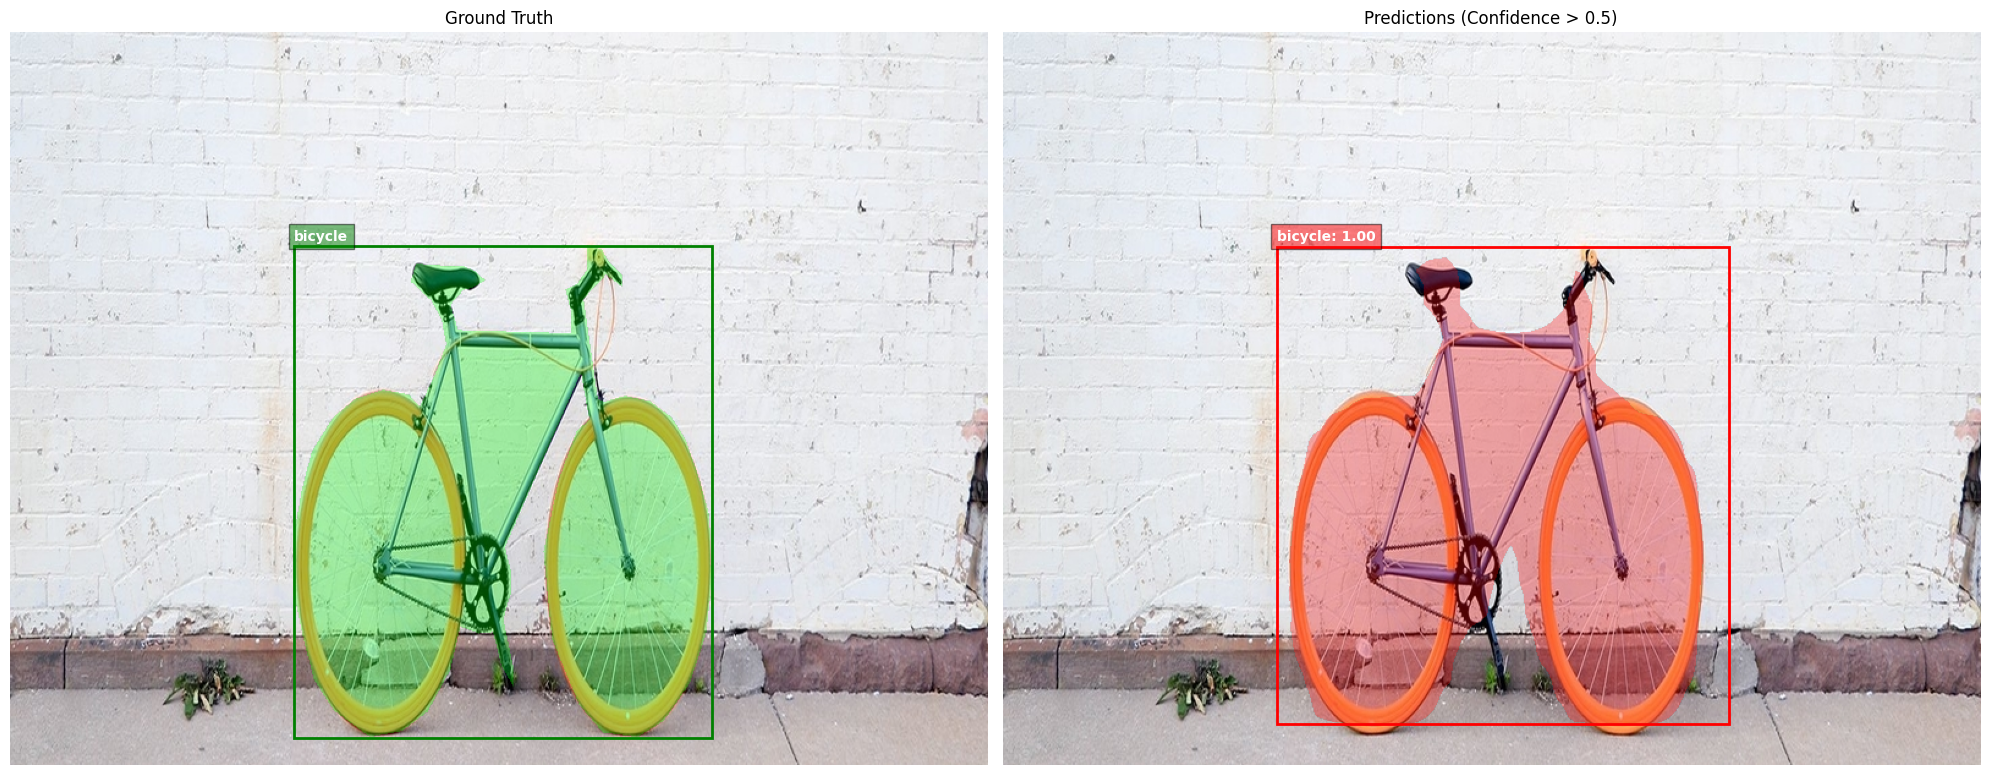

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Configure device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Configure path
dataset_dir = "/content/drive/MyDrive/TrafficDataset/traffic_detector_dataset"

# Ensure val_dataset is initialized
val_dataset = TrafficDataset(
    root_dir=os.path.join(dataset_dir, "val"),
    annotation_file=os.path.join(dataset_dir, "val.json")
)

# Setup class names (background + 8 traffic classes)
class_names = ['background', 'bicycle', 'bus', 'car', 'motorcycle', 'person', 'stop sign', 'traffic light', 'truck']

# Confirm dataset size and select safe index
dataset_size = len(val_dataset)
print(f"Validation dataset contains {dataset_size} samples.")

target_index = 5
if dataset_size <= target_index:
    target_index = dataset_size - 1
    print(f"Fewer than 6 samples available. Selecting last index: {target_index}")

# Switch model to evaluation
model.to(device)
model.eval()

# Load a sample from validation dataset
img, target = val_dataset[target_index]
with torch.no_grad():
    prediction = model([img.to(device)])[0]

# Setup plotting
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

# Plot Ground Truth
ax1.imshow(img.permute(1, 2, 0).numpy())
ax1.set_title("Ground Truth")
ax1.axis('off')

for box, label, mask in zip(target['boxes'].numpy(), target['labels'].numpy(), target['masks'].numpy()):
    rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], linewidth=2, edgecolor='green', facecolor='none')
    ax1.add_patch(rect)
    ax1.text(box[0], box[1] - 5, class_names[label], color='white', weight='bold', bbox=dict(facecolor='green', alpha=0.5))

    masked_img = np.zeros((mask.shape[0], mask.shape[1], 4))
    masked_img[mask == 1] = [0, 1, 0, 0.3]
    ax1.imshow(masked_img)

# Plot Prediction
ax2.imshow(img.permute(1, 2, 0).numpy())
ax2.set_title("Predictions (Confidence > 0.5)")
ax2.axis('off')

pred_boxes = prediction['boxes'].cpu().numpy()
pred_labels = prediction['labels'].cpu().numpy()
pred_scores = prediction['scores'].cpu().numpy()
pred_masks = prediction['masks'].cpu().numpy()

for box, label, score, mask in zip(pred_boxes, pred_labels, pred_scores, pred_masks):
    if score > 0.5:
        rect = patches.Rectangle((box[0], box[1]), box[2]-box[0], box[3]-box[1], linewidth=2, edgecolor='red', facecolor='none')
        ax2.add_patch(rect)
        ax2.text(box[0], box[1] - 5, f"{class_names[label]}: {score:.2f}", color='white', weight='bold', bbox=dict(facecolor='red', alpha=0.5))

        # Binarize prediction mask at 0.5 threshold
        binary_mask = mask[0] > 0.5
        masked_img = np.zeros((binary_mask.shape[0], binary_mask.shape[1], 4))
        masked_img[binary_mask] = [1, 0, 0, 0.3]
        ax2.imshow(masked_img)

plt.tight_layout()
plt.show()

In [9]:

import os

folder = "/content/drive/MyDrive/MaskRCNN"

print("Folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    print("\nFiles found in your MaskRCNN folder:")
    for name in os.listdir(folder):
        path = os.path.join(folder, name)
        if os.path.isfile(path):
            print(f"{name} — {os.path.getsize(path) / (1024**2):.2f} MB")
        else:
            print(f"{name}/ (folder)")
else:
    print("MaskRCNN folder not found. Check Google Drive mounting.")


Folder exists: True

Files found in your MaskRCNN folder:
maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth — 169.84 MB
traffic_maskrcnn_best.pth — 336.18 MB
training_history.csv — 0.00 MB


In [10]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/MaskRCNN/traffic_maskrcnn_best.pth"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>